# <center>IMRT SCP Tutorial</center>

Step-and-shoot IMRT delivers a few apertures per beam, each with its own monitor units. The usual
route is to optimize a continuous fluence map and then sequence it into apertures, so deliverability
is enforced only *after* the optimization.

`portpy.photon.imrt_scp` optimizes the aperture shapes and their MUs **directly**, reusing the VMAT
SCP machinery: `create_imrt_plan` gives each beam its own apertures, column generation builds a
starting set, and sequential convex programming then refines every leaf position together. Every
iterate is deliverable.

This notebook plans `Lung_Patient_6` on the **beams chosen by the human planner, each delivering
10 apertures** (70 segments in total), using PortPy's shipped lung clinical criteria and optimization template. For how
close such a plan gets to a global optimum, see
[imrt_global_optimal.ipynb](https://github.com/PortPy-Project/PortPy/blob/master/examples/imrt_global_optimal.ipynb).

### 1) Accessing the portpy data (DataExplorer class)

In [1]:
import sys
sys.path.append('..')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import portpy.photon as pp

C:\Users\JhanwarG\.conda\envs\PortPy\Lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# specify the patient data location.
data_dir = r'../data'
# Use PortPy DataExplorer class to explore PortPy data
data = pp.DataExplorer(data_dir=data_dir)
data.patient_id = 'Lung_Patient_6'

# Load ct and structure set for the above patient using CT and Structures class
ct = pp.CT(data)
structs = pp.Structures(data)

# with no beam_ids, PortPy uses the beams selected by an expert human planner
beams = pp.Beams(data)

# load clinical criteria from the config files for which plan to be optimized
clinical_criteria = pp.ClinicalCriteria(data, protocol_name='Lung_2Gy_30Fx')

# Loading hyper-parameter values for optimization problem
opt_params = data.load_config_opt_params(protocol_name='Lung_2Gy_30Fx_vmat')

# Creating optimization structures (i.e., Rinds, PTV-GTV)
structs.create_opt_structures(opt_params=opt_params, clinical_criteria=clinical_criteria)

# Loading influence matrix
inf_matrix = pp.InfluenceMatrix(ct=ct, structs=structs, beams=beams)

# scale influence matrix to get correct MU for TPS import
inf_matrix_scale_factor = opt_params['opt_parameters'].get('inf_matrix_scale_factor', 1)
inf_matrix.A = inf_matrix.A * np.float32(inf_matrix_scale_factor)

# Create a plan using ct, structures, beams and influence matrix. Clinical criteria is optional
my_plan = pp.Plan(ct=ct, structs=structs, beams=beams, inf_matrix=inf_matrix,
                  clinical_criteria=clinical_criteria)

Creating optimization structures.. It may take some time due to dilation


Optimization structures created!!


Creating BEV..


Loading sparse influence matrix...
Done


### 2) Creating apertures for each beam (create_imrt_plan)

`create_imrt_plan` gives every beam `num_apertures` apertures of its own by replicating its
influence-matrix columns, so a beamlet's fluence is the sum of the apertures that leave it open.
It returns a new plan and leaves the one above untouched.

In [3]:
# 10 apertures per beam -> 70 segments in total
imrt_plan = pp.create_imrt_plan(my_plan, num_apertures=10)

### 3) Optimize the IMRT plan (PortPy.Photon.ImrtScp module)

If hyperparameter `initial_leaf_pos` is set to `CG` (Column Generation), the apertures are
initialized by column generation, which greedily adds the aperture with the steepest gradient on
the objective. This plan is not necessarily optimal, but gives SCP a good starting point. Set
`opt_params['opt_parameters']['initial_leaf_pos'] = 'BEV'` to skip it.

In [4]:
if opt_params['opt_parameters']['initial_leaf_pos'].lower() == 'cg':
    col_gen = pp.ImrtOptimizationColGen(my_plan=imrt_plan, opt_params=opt_params)
    sol_col_gen = col_gen.run_col_gen_algo(solver='MOSEK', verbose=False, accept_unknown=True)

In [5]:
# Initialize Optimization
imrt_opt = pp.ImrtScpOptimization(my_plan=imrt_plan, opt_params=opt_params)
# Run Sequential convex algorithm for optimising the plan. The final result will be stored in
# sol and convergence will store the convergence history (i.e., results of each iteration)
convergence = imrt_opt.run_sequential_cvx_algo(solver='MOSEK', verbose=False)
sol = convergence[imrt_opt.best_iteration]  # get best solution
sol['inf_matrix'] = imrt_plan.inf_matrix  # reference for evaluation and visualization

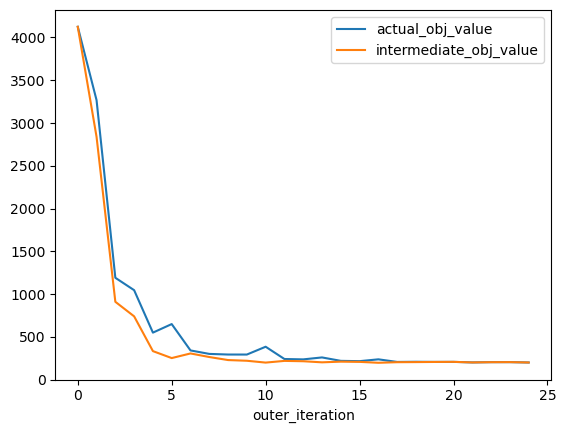

In [6]:
# Visualize convergence. The convergence dataframe contains the following columns:
df = pd.DataFrame(convergence, columns=['outer_iteration', 'inner_iteration', 'step_size_f_b',
                                        'forward_backward', 'intermediate_obj_value',
                                        'actual_obj_value', 'accept'])
# We can, for example, plot the actual and intermediate objective values against the outer iteration
df.plot(x='outer_iteration', y=['actual_obj_value', 'intermediate_obj_value'])
plt.show()

### 4) Visualizing the plan (Visualization class)

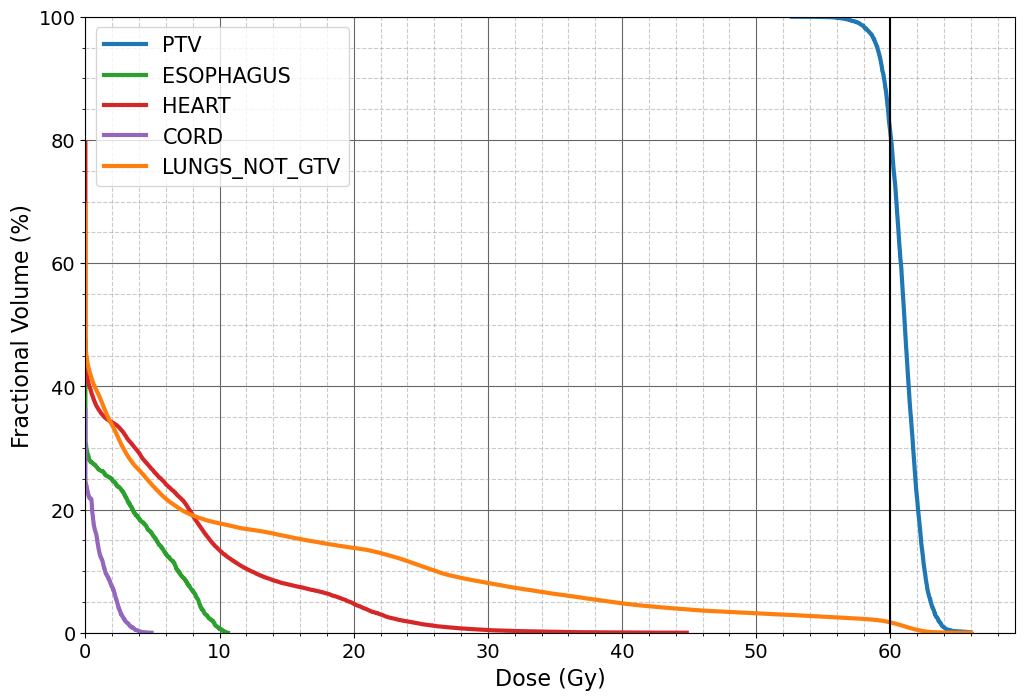

In [7]:
# plot dvh for the above structures
fig, ax = plt.subplots(figsize=(12, 8))
struct_names = ['PTV', 'ESOPHAGUS', 'HEART', 'CORD', 'LUNGS_NOT_GTV']
pp.Visualization.plot_dvh(imrt_plan, sol=sol, struct_names=struct_names, ax=ax)
plt.show()

<Axes: title={'center': 'Axial View - Slice #: 60'}>

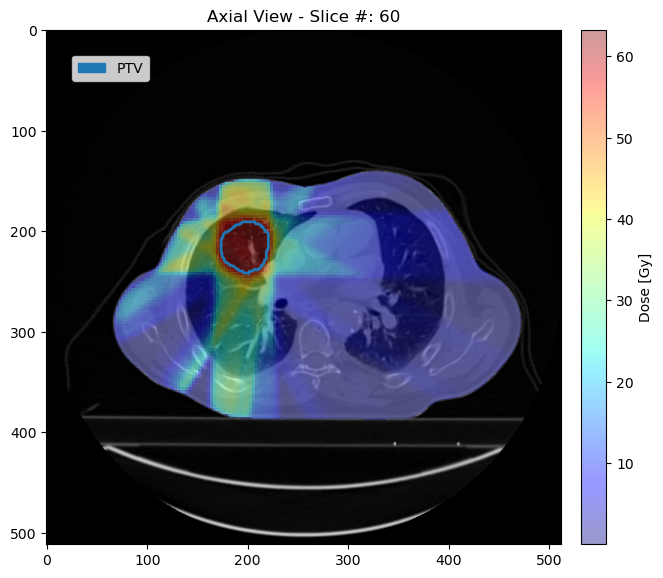

In [8]:
# plot 2d axial slice for the given solution and display the structures contours on the slice
pp.Visualization.plot_2d_slice(my_plan=imrt_plan, sol=sol, slice_num=60, struct_names=['PTV'])

### 5) Evaluating the plan (Evaluation class)

In [9]:
# visualize plan metrics and compare them against the clinical criteria
pp.Evaluation.display_clinical_criteria(imrt_plan, sol=sol, clinical_criteria=clinical_criteria)

,Constraint,Structure Name,Limit,Goal,Plan Value
0,Max Dose,GTV,69.0Gy,66.0Gy,63.61
1,Max Dose,PTV,69.0Gy,66.0Gy,66.00
2,Max Dose,ESOPHAGUS,66.0Gy,,10.60
3,Mean Dose,ESOPHAGUS,34.0Gy,21.0Gy,1.55
4,V(60.0Gy),ESOPHAGUS,17.0%,,0.00
5,Max Dose,HEART,66.0Gy,,44.81
6,Mean Dose,HEART,27.0Gy,20.0Gy,3.69
7,V(30.0Gy),HEART,50.0%,,0.44
8,V(30.0Gy),HEART,,48.0%,0.44
9,Max Dose,LUNG_L,66.0Gy,,10.42


### 6) Saving and loading the plan for future use (utils)

In [11]:
# Comment/Uncomment these lines to save and load the pickle file for plans and optimal solution
pp.save_plan(imrt_plan, plan_name='my_plan_imrt_scp.pkl', path=os.path.join(r'C:\temp', data.patient_id))
pp.save_optimal_sol(sol, sol_name='sol_imrt_scp.pkl', path=os.path.join(r'C:\temp', data.patient_id))
# imrt_plan = pp.load_plan(plan_name='my_plan_imrt_scp.pkl', path=os.path.join(r'C:\temp', data.patient_id))
# sol = pp.load_optimal_sol(sol_name='sol_imrt_scp.pkl', path=os.path.join(r'C:\temp', data.patient_id))